# Avaliação GraphRAG 
**Objetivo:** Avaliar se o sistema identifica corretamente a doença principal de cada prontuário.
**Ground truth:** anotação manual de 141 prontuários.

In [1]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.1.1
[notice] To update, run: C:\Users\Matheus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
)

import warnings
warnings.filterwarnings('ignore')

# Paleta clínica
COR_TUNED   = '#2E86AB'   # azul
COR_BASE    = '#E84855'   # vermelho
COR_OK      = '#3BB273'   # verde
COR_NEUTRO  = '#A8DADC'   # azul claro

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'font.family': 'DejaVu Sans',
})

print('OK')

OK


## 1. Configuração de caminhos

In [ ]:

GROUND_TRUTH_CSV   = "../progresso/ground_truth_anotado.csv"
DATASET_TUNED_CSV  = "../results/dataset/maio-2026/dataset-prompt-tuning-doenca-normalizada-20260509.csv"
DATASET_BASE_CSV   = None  # informação sem o tuning

CLASSES = [
    'cirrose_hepatica', 'esquistossomose', 'hepatite_c', 'hepatite_b',
    'esteatose_hepatica', 'hipertensao_portal', 'hemorragia_digestiva_alta', 'pbe',
]
LABELS_PT = {
    'cirrose_hepatica':          'Cirrose hepática',
    'esquistossomose':           'Esquistossomose',
    'hepatite_c':                'Hepatite C',
    'hepatite_b':                'Hepatite B',
    'esteatose_hepatica':        'Esteatose hepática',
    'hipertensao_portal':        'Hipertensão portal',
    'hemorragia_digestiva_alta': 'Hemorragia digestiva alta',
    'pbe':                       'PBE',
    'nenhuma':                   'Nenhuma',
}

MAPA = {
    'CIRROSE': 'cirrose_hepatica', 'CIRROSE HEPATICA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA': 'cirrose_hepatica', 'CIRROSE HEPÁTICA DESCOMPENSADA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA ALCOÓLICA': 'cirrose_hepatica', 'CIRROSE HEPÁTICA VIRAL C': 'cirrose_hepatica',
    'CIRROSE MICRONODULAR': 'cirrose_hepatica', 'CIRROSE DESCOMPENSADA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA CRÔNICA': 'cirrose_hepatica',
    'HIPERTENSAO PORTAL': 'hipertensao_portal', 'HIPERTENSÃO PORTAL': 'hipertensao_portal',
    'HIPERTENSÃO PORTA': 'hipertensao_portal', 'SINDROME DE HIPERTENSAO PORTAL': 'hipertensao_portal',
    'SÍNDROME DE HIPERTENSÃO PORTAL': 'hipertensao_portal', 'SÍNDROME DA HIPERTENSÃO PORTAL': 'hipertensao_portal',
    'HIPERTENSÃO PORTAL NÃO CIRRÓTICA': 'hipertensao_portal', 'HIPERTENSÃO PORTAL NÃO-CIRRÓTICA': 'hipertensao_portal',
    'EHE/HP': 'hipertensao_portal',
    'ESQUISTOSSOMOSE': 'esquistossomose', 'EQUISTOSSOMOSE': 'esquistossomose',
    'ESQUISTOSSOMOSE HEPATOESPLENICA': 'esquistossomose', 'ESQUISTOSSOMOSE HEPATOESPLÊNICA': 'esquistossomose',
    'ESQUISTOSSOMOSE HEPATOESPLÊNICA (EHE)': 'esquistossomose', 'ESQUISTOSSOMOSE MANSONI': 'esquistossomose',
    'ESQUISTOSSOMOSE MANSÔNICA': 'esquistossomose', 'EHE': 'esquistossomose',
    'HEPATITE C': 'hepatite_c', 'HEPATITE C (HCV)': 'hepatite_c',
    'HEPATITE C CRÔNICA': 'hepatite_c', 'HEPATITE CRÔNICA VIRAL': 'hepatite_c',
    'HEPATITE B': 'hepatite_b', 'HEPATITE B (HBV)': 'hepatite_b',
    'HEPATITE B CRONICA': 'hepatite_b', 'HEPATITE B INATIVA': 'hepatite_b',
    'HEPATITE B RESOLVIDA': 'hepatite_b', 'HEPATITE CRÔNICA B': 'hepatite_b',
    'HEPATITE CRÔNICA VIRAL B': 'hepatite_b', 'VÍRUS B (HEPATITE B)': 'hepatite_b',
    'ESTEATOSE': 'esteatose_hepatica', 'ESTEATOSE HEPATICA': 'esteatose_hepatica',
    'ESTEATOSE HEPÁTICA': 'esteatose_hepatica', 'ESTEATOSE HEPATICA DIFUSA': 'esteatose_hepatica',
    'DHGNA': 'esteatose_hepatica', 'NAFLD': 'esteatose_hepatica',
    'MASLD': 'esteatose_hepatica', 'MASH': 'esteatose_hepatica', 'NASH': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA (DHGNA)': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA (MASH)': 'esteatose_hepatica',
    'ESTEATO-HEPATITE NÃO ALCOÓLICA': 'esteatose_hepatica',
    'ESTEATO-HEPATITE NÃO ALCOÓLICA (NASH)': 'esteatose_hepatica',
    'ESTEATOHEPATITE': 'esteatose_hepatica', 'ESTEATOHEPATITE NÃO ALCOÓLICA': 'esteatose_hepatica',
    'HDA': 'hemorragia_digestiva_alta', 'HEMORRAGIA DIGESTIVA ALTA': 'hemorragia_digestiva_alta',
    'HDA (HEMORRAGIA DIGESTIVA ALTA)': 'hemorragia_digestiva_alta', 'HDA VARICOSA': 'hemorragia_digestiva_alta',
    'HEMORRAGIA DIGESTIVA ALTA VARICOSA': 'hemorragia_digestiva_alta', 'HEMORRAGIA VARICOSA': 'hemorragia_digestiva_alta',
    'PBE': 'pbe', 'PERITONITE BACTERIANA ESPONTÂNEA': 'pbe',
    'PBE (PERITONITE BACTERIANA ESPONTÂNEA)': 'pbe', 'PERITONITE BACTERIANA ESPONTANEA': 'pbe',
}

def normaliza_dataset(csv_path):
    df = pd.read_csv(csv_path, dtype=str).fillna('')
    df['prontuario_id'] = df['prontuario_id'].str.strip()
    df['classe'] = df['condicao_normalizada'].str.upper().str.strip().map(MAPA)
    principal = (
        df[df['classe'].notna()]
        .groupby('prontuario_id')['classe']
        .agg(lambda x: x.value_counts().index[0])
        .reset_index()
        .rename(columns={'classe': 'doenca_prevista'})
    )
    return principal

def bootstrap_f1(y_true, y_pred, n=5000):
    scores = []
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    for _ in range(n):
        idx = np.random.choice(len(y_true), len(y_true), replace=True)
        try:
            _, _, f1, _ = precision_recall_fscore_support(y_true[idx], y_pred[idx], average='macro', zero_division=0)
            scores.append(f1)
        except: pass
    return np.percentile(scores, [2.5, 97.5])

print('Configuração carregada.')

Configuração carregada.


## 2. Carga dos dados

In [4]:
gt = pd.read_csv(GROUND_TRUTH_CSV, dtype=str).fillna('')
gt['prontuario_id'] = gt['prontuario_id'].str.strip()

prev_tuned = normaliza_dataset(DATASET_TUNED_CSV)
prev_base  = normaliza_dataset(DATASET_BASE_CSV) if DATASET_BASE_CSV else None

# Merge ground truth com previsões
df = gt[['prontuario_id', 'doenca_principal', 'confianca']].merge(
    prev_tuned.rename(columns={'doenca_prevista': 'prev_tuned'}),
    on='prontuario_id', how='left'
)
if prev_base is not None:
    df = df.merge(
        prev_base.rename(columns={'doenca_prevista': 'prev_base'}),
        on='prontuario_id', how='left'
    )
    df['prev_base'] = df['prev_base'].fillna('nenhuma')

df['prev_tuned'] = df['prev_tuned'].fillna('nenhuma')

# Separar FP puros dos casos avaliáveis
df_fp   = df[df['doenca_principal'] == 'nenhuma'].copy()
df_eval = df[df['doenca_principal'] != 'nenhuma'].copy()

print(f'total         : {len(gt)}')
print(f'Casos avaliáveis (com GT)  : {len(df_eval)}')
print(f'Falsos positivos puros     : {len(df_fp)}')
print(f'\nDistribuição do ground truth:')
print(df_eval['doenca_principal'].map(LABELS_PT).value_counts().to_string())

total         : 141
Casos avaliáveis (com GT)  : 109
Falsos positivos puros     : 32

Distribuição do ground truth:
doenca_principal
Esteatose hepática           41
Cirrose hepática             16
Esquistossomose              16
Hipertensão portal           15
Hepatite B                   10
Hepatite C                    5
Hemorragia digestiva alta     5
PBE                           1


## 3. Distribuição do ground truth

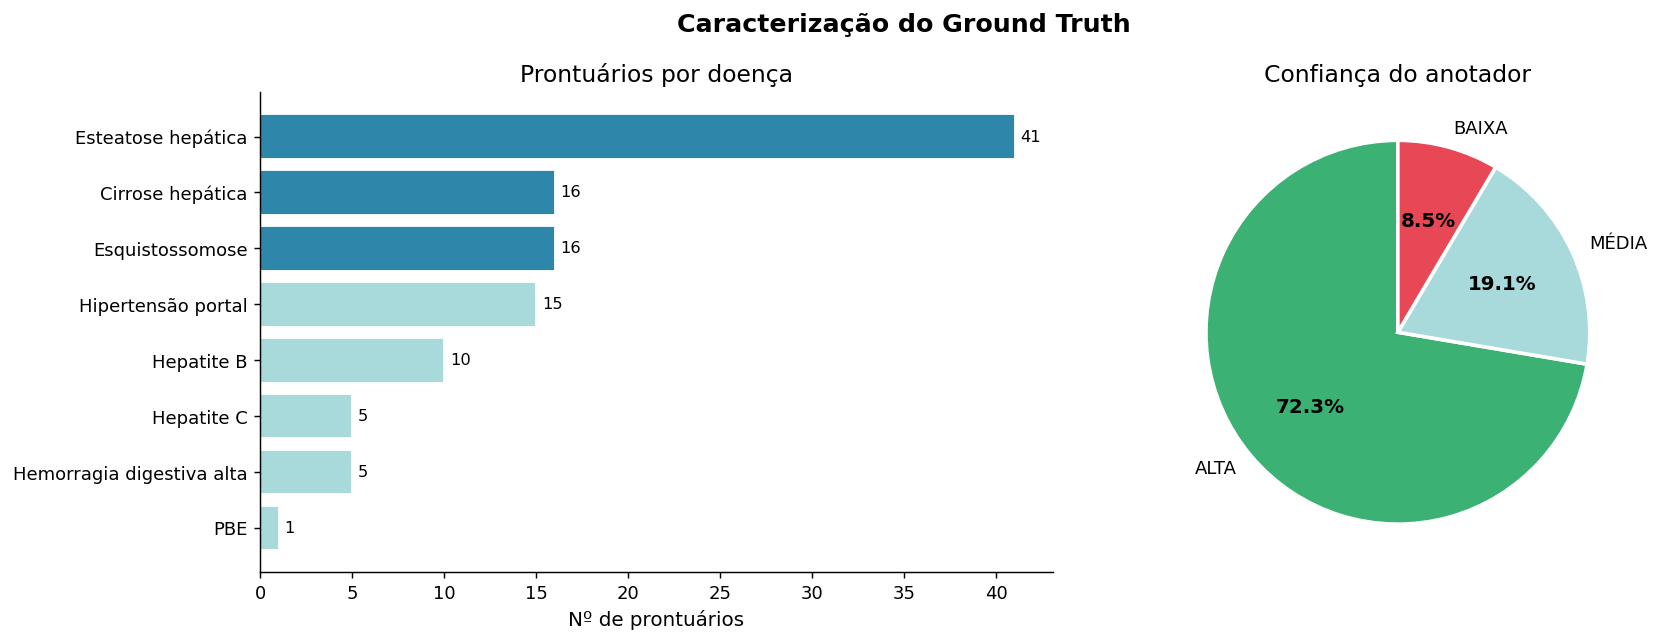

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Caracterização do Ground Truth', fontsize=14, fontweight='bold')

# Distribuição por doença
ax = axes[0]
dist = df_eval['doenca_principal'].map(LABELS_PT).value_counts()
cores = [COR_TUNED if i < 3 else COR_NEUTRO for i in range(len(dist))]
bars = ax.barh(dist.index[::-1], dist.values[::-1], color=cores[::-1], edgecolor='white')
for bar, v in zip(bars, dist.values[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2, str(v), va='center', fontsize=9)
ax.set_title('Prontuários por doença')
ax.set_xlabel('Nº de prontuários')

# Distribuição de confiança
ax = axes[1]
conf = gt['confianca'].value_counts()
cores_conf = {'ALTA': COR_OK, 'MÉDIA': COR_NEUTRO, 'BAIXA': COR_BASE}
wedges, texts, autotexts = ax.pie(
    conf.values,
    labels=conf.index,
    colors=[cores_conf.get(c, COR_NEUTRO) for c in conf.index],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts: at.set_fontsize(11); at.set_fontweight('bold')
ax.set_title('Confiança do anotador')

plt.tight_layout()
plt.savefig('fig_ground_truth.png', bbox_inches='tight')
plt.show()

## 4. Métricas do sistema Prompt-Tuned

In [7]:
y_true = df_eval['doenca_principal'].tolist()
y_pred = df_eval['prev_tuned'].tolist()

classes_presentes = sorted(set(y_true))

acc   = accuracy_score(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(y_true, y_pred, average='macro',    zero_division=0)
p_wtd, r_wtd, f1_wtd, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
ic_f1 = bootstrap_f1(y_true, y_pred)

p_cls, r_cls, f1_cls, sup_cls = precision_recall_fscore_support(
    y_true, y_pred, labels=classes_presentes, average=None, zero_division=0
)

df_metricas = pd.DataFrame({
    'Doença':    [LABELS_PT.get(c, c) for c in classes_presentes],
    'Precision': p_cls.round(3),
    'Recall':    r_cls.round(3),
    'F1':        f1_cls.round(3),
    'Suporte':   sup_cls.astype(int),
})

print('=' * 55)
print('SISTEMA PROMPT-TUNED')
print('=' * 55)
print(f'Casos avaliados   : {len(df_eval)}')
print(f'Accuracy          : {acc:.4f}  ({acc*100:.1f}%)')
print(f'Cohen Kappa       : {kappa:.4f}')
print(f'F1 macro          : {f1_mac:.4f}  IC 95%: [{ic_f1[0]:.4f}, {ic_f1[1]:.4f}]')
print(f'F1 weighted       : {f1_wtd:.4f}')
print(f'Precision macro   : {p_mac:.4f}')
print(f'Recall macro      : {r_mac:.4f}')
print(f'\nFalsos positivos puros : {len(df_fp)}')
print('\nPor classe:')
display(df_metricas)

df_metricas.to_csv('metricas_por_classe_tuned.csv', index=False, encoding='utf-8-sig')

SISTEMA PROMPT-TUNED
Casos avaliados   : 109
Accuracy          : 0.6147  (61.5%)
Cohen Kappa       : 0.5163
F1 macro          : 0.5262  IC 95%: [0.3848, 0.6757]
F1 weighted       : 0.6206
Precision macro   : 0.5251
Recall macro      : 0.5804

Falsos positivos puros : 32

Por classe:


,Doença,Precision,Recall,F1,Suporte
0,Cirrose hepática,0.409,0.562,0.474,16
1,Esquistossomose,0.818,0.562,0.667,16
2,Esteatose hepática,0.811,0.732,0.769,41
3,Hemorragia digestiva alta,0.500,1.000,0.667,5
4,Hepatite B,0.500,0.300,0.375,10
5,Hepatite C,0.750,0.600,0.667,5
6,Hipertensão portal,0.438,0.467,0.452,15
7,PBE,0.500,1.000,0.667,1


## 5. Visualização — Precision, Recall e F1 por classe

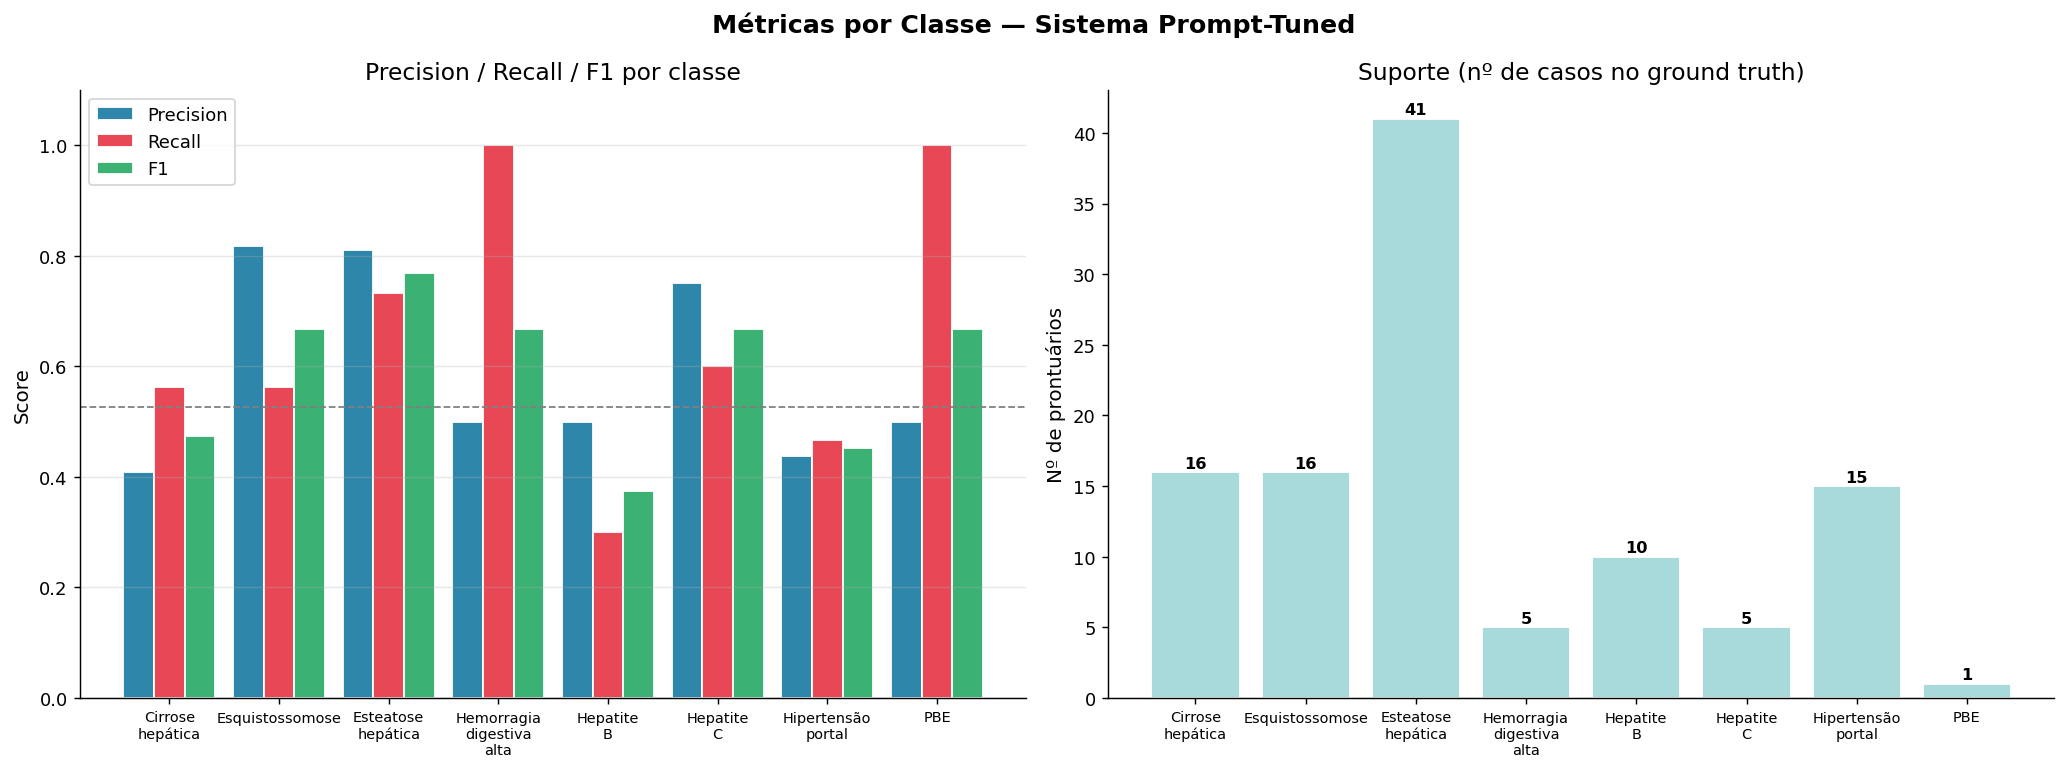

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Métricas por Classe', fontsize=14, fontweight='bold')

doencas = df_metricas['Doença'].tolist()
x = np.arange(len(doencas))
w = 0.28

# Precision, Recall, F1
ax = axes[0]
ax.bar(x - w, df_metricas['Precision'], width=w, label='Precision', color='#2E86AB', edgecolor='white')
ax.bar(x,     df_metricas['Recall'],    width=w, label='Recall',    color='#E84855', edgecolor='white')
ax.bar(x + w, df_metricas['F1'],        width=w, label='F1',        color='#3BB273', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels([d.replace(' ', '\n') for d in doencas], fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Precision / Recall / F1 por classe')
ax.legend()
ax.axhline(f1_mac, color='gray', linestyle='--', linewidth=1, label=f'F1 macro={f1_mac:.2f}')
ax.grid(axis='y', alpha=0.3)

# Suporte
ax = axes[1]
bars = ax.bar(doencas, df_metricas['Suporte'], color=COR_NEUTRO, edgecolor='white')
for bar, v in zip(bars, df_metricas['Suporte']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(v), ha='center', fontsize=9, fontweight='bold')
ax.set_xticklabels([d.replace(' ', '\n') for d in doencas], fontsize=8)
ax.set_title('Suporte')
ax.set_ylabel('Nº de prontuários')

plt.tight_layout()
plt.savefig('fig_metricas_por_classe.png', bbox_inches='tight')
plt.show()

## 6. Matriz de confusão

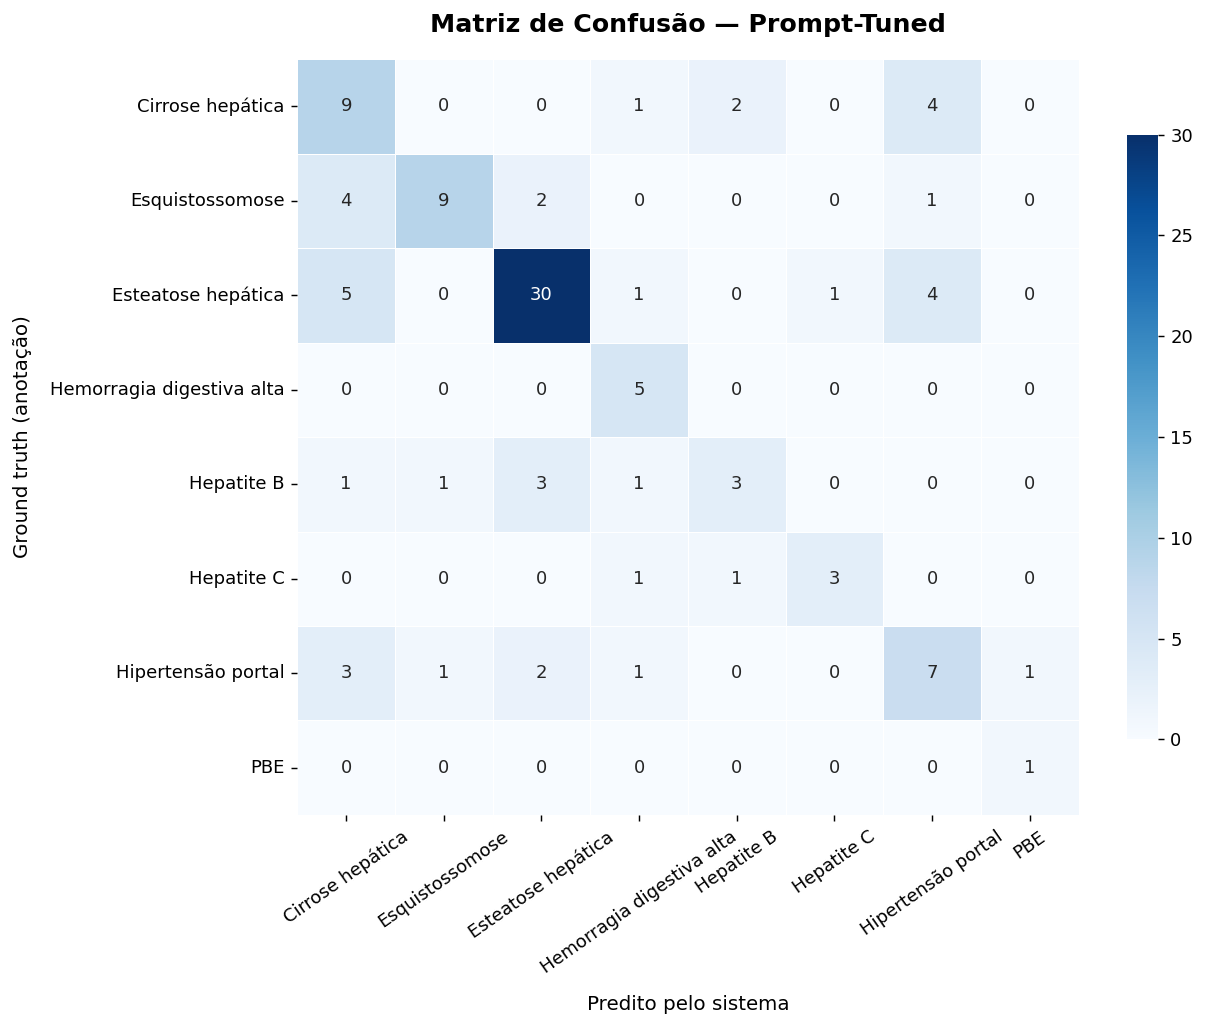

In [9]:
cm = confusion_matrix(y_true, y_pred, labels=classes_presentes)
labels_plot = [LABELS_PT.get(c, c) for c in classes_presentes]

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels_plot,
    yticklabels=labels_plot,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'shrink': 0.8}
)

ax.set_title('Matriz de Confusão — Prompt-Tuned', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Predito pelo sistema', fontsize=11, labelpad=10)
ax.set_ylabel('Ground truth (anotação)', fontsize=11, labelpad=10)
ax.tick_params(axis='x', rotation=35)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('fig_matriz_confusao_tuned.png', bbox_inches='tight')
plt.show()

# Salva CSV
pd.DataFrame(cm, index=labels_plot, columns=labels_plot).to_csv(
    'matriz_confusao_tuned.csv', encoding='utf-8-sig'
)

## 7. Análise de erros

Falsos positivos : 32
(sistema identificou doença, mas prontuário não tinha nenhuma das 8 classes)



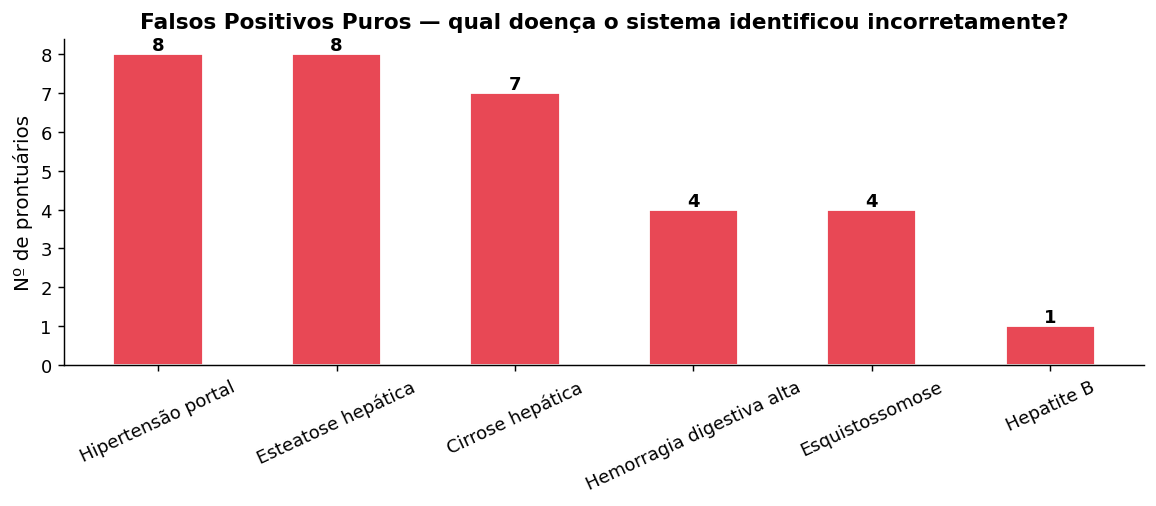


Erros de classificação (confundiu uma classe com outra): 42


,prontuario_id,GT,Previsto,confianca
0,10001436,Cirrose hepática,Hipertensão portal,ALTA
1,10002061,Hepatite B,Nenhuma,MÉDIA
2,10005627,Esquistossomose,Esteatose hepática,ALTA
5,10025831,Hepatite B,Esteatose hepática,ALTA
13,10086429,Cirrose hepática,Hipertensão portal,ALTA
16,10109056,Esquistossomose,Cirrose hepática,MÉDIA
17,10113876,Cirrose hepática,Hepatite B,ALTA
18,10191732,Esquistossomose,Esteatose hepática,ALTA
19,10197374,Hepatite C,Hemorragia digestiva alta,ALTA
20,10197663,Hepatite B,Esteatose hepática,MÉDIA


In [6]:
print(f'Falsos positivos : {len(df_fp)}')
print('(sistema identificou doença, mas prontuário não tinha nenhuma das 8 classes)\n')

if len(df_fp) > 0:
    fp_dist = df_fp['prev_tuned'].map(LABELS_PT).value_counts()

    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(fp_dist.index, fp_dist.values, color=COR_BASE, edgecolor='white', width=0.5)
    for bar, v in zip(bars, fp_dist.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                str(v), ha='center', fontweight='bold')
    ax.set_title('Falsos Positivos Puros — qual doença o sistema identificou incorretamente?',
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('Nº de prontuários')
    ax.tick_params(axis='x', rotation=25)
    plt.tight_layout()
    plt.savefig('fig_falsos_positivos_puros.png', bbox_inches='tight')
    plt.show()

# Erros de classificação (confundiu classe A com classe B)
df_erros = df_eval[df_eval['doenca_principal'] != df_eval['prev_tuned']].copy()
print(f'\nErros de classificação (confundiu uma classe com outra): {len(df_erros)}')
if len(df_erros) > 0:
    df_erros['GT']     = df_erros['doenca_principal'].map(LABELS_PT)
    df_erros['Previsto'] = df_erros['prev_tuned'].map(LABELS_PT)
    display(df_erros[['prontuario_id', 'GT', 'Previsto', 'confianca']].head(20))

## 8. Comparação Baseline vs Prompt-Tuned *(executar só se tiver baseline)*

In [ ]:
if prev_base is None:
    print('Baseline não configurado. Defina DATASET_BASE_CSV na célula 1 para ativar esta seção.')
else:
    y_base = df_eval['prev_base'].tolist()

    acc_b  = accuracy_score(y_true, y_base)
    kap_b  = cohen_kappa_score(y_true, y_base)
    _, _, f1_mac_b, _ = precision_recall_fscore_support(y_true, y_base, average='macro', zero_division=0)
    _, _, f1_wtd_b, _ = precision_recall_fscore_support(y_true, y_base, average='weighted', zero_division=0)
    ic_b   = bootstrap_f1(y_true, y_base)

    p_b, r_b, f1_b, _ = precision_recall_fscore_support(
        y_true, y_base, labels=classes_presentes, average=None, zero_division=0
    )

    # Tabela comparativa
    df_comp = pd.DataFrame({
        'Métrica':       ['Accuracy', 'F1 macro', 'F1 weighted', "Cohen's Kappa"],
        'Baseline':      [acc_b,  f1_mac_b, f1_wtd_b, kap_b],
        'Prompt-Tuned':  [acc,    f1_mac,   f1_wtd,   kappa],
        'Delta (T-B)':   [acc-acc_b, f1_mac-f1_mac_b, f1_wtd-f1_wtd_b, kappa-kap_b],
    }).round(4)
    display(df_comp)

    # Gráfico comparativo por classe
    fig, ax = plt.subplots(figsize=(13, 5))
    x  = np.arange(len(classes_presentes))
    w  = 0.35
    ax.bar(x - w/2, f1_b,   width=w, label='Baseline',      color=COR_BASE,  edgecolor='white')
    ax.bar(x + w/2, f1_cls, width=w, label='Prompt-Tuned', color=COR_TUNED, edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS_PT.get(c, c).replace(' ', '\n') for c in classes_presentes], fontsize=9)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel('F1-score')
    ax.set_title('F1 por Classe — Baseline vs Prompt-Tuned', fontsize=13, fontweight='bold')
    ax.legend()
    ax.axhline(f1_mac,   color=COR_TUNED, linestyle='--', linewidth=1, alpha=0.6, label='F1 macro tuned')
    ax.axhline(f1_mac_b, color=COR_BASE,  linestyle='--', linewidth=1, alpha=0.6, label='F1 macro base')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('fig_comparacao_baseline_tuned.png', bbox_inches='tight')
    plt.show()

    # Testes estatísticos
    from scipy.stats import wilcoxon
    try:
        from statsmodels.stats.contingency_tables import mcnemar as mc_test
        acerto_t = (np.array(y_true) == np.array(y_pred)).astype(int)
        acerto_b = (np.array(y_true) == np.array(y_base)).astype(int)
        b = ((acerto_t == 1) & (acerto_b == 0)).sum()
        c = ((acerto_t == 0) & (acerto_b == 1)).sum()
        mc = mc_test([[0, b], [c, 0]])
        print(f'\nTestes estatísticos:')
        print(f'  McNemar p-valor  : {mc.pvalue:.4f}  {"(p<0.05 — significativo)" if mc.pvalue < 0.05 else "(não significativo)"}')
        if not np.all(f1_cls == f1_b):
            _, p_w = wilcoxon(f1_cls, f1_b)
            print(f'  Wilcoxon p-valor : {p_w:.4f}  {"(p<0.05 — significativo)" if p_w < 0.05 else "(não significativo)"}')
        print(f'\nIC 95% F1 macro (bootstrap):')
        print(f'  Baseline      : [{ic_b[0]:.4f}, {ic_b[1]:.4f}]')
        print(f'  Prompt-Tuned  : [{ic_f1[0]:.4f}, {ic_f1[1]:.4f}]')
    except ImportError:
        print('Instale statsmodels: pip install statsmodels')

## 9. Resumo executivo

In [ ]:
print('=' * 55)
print('RESUMO EXECUTIVO — para o TCC')
print('=' * 55)
print(f'Prontuários anotados      : {len(gt)}')
print(f'Casos avaliáveis          : {len(df_eval)}')
print(f'Falsos positivos puros    : {len(df_fp)}')
print()
print(f'Accuracy (prompt-tuned)   : {acc:.4f}  ({acc*100:.1f}%)')
print(f'F1 macro                  : {f1_mac:.4f}  IC [{ic_f1[0]:.4f}, {ic_f1[1]:.4f}]')
print(f"Cohen's Kappa             : {kappa:.4f}")
print()
melhor = df_metricas.sort_values('F1', ascending=False).iloc[0]
pior   = df_metricas.sort_values('F1').iloc[0]
print(f'Melhor classe (F1)        : {melhor["Doença"]} = {melhor["F1"]:.3f}')
print(f'Pior classe (F1)          : {pior["Doença"]} = {pior["F1"]:.3f}')
print()
print('Figuras geradas:')
print('  fig_ground_truth.png')
print('  fig_metricas_por_classe.png')
print('  fig_matriz_confusao_tuned.png')
print('  fig_falsos_positivos_puros.png')
if prev_base: print('  fig_comparacao_baseline_tuned.png')